In [1]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Carregando a base de gols do futebol internacional
url = "https://raw.githubusercontent.com/martj42/international_results/master/goalscorers.csv"
df = pd.read_csv(url)

# 2. Limpeza dos dados (recriando o df_limpo do notebook anterior)
df_limpo = df.drop(columns=["assist"]).copy()
df_limpo["scorer"] = df_limpo["scorer"].fillna("Desconhecido")
df_limpo = df_limpo.dropna(subset=["minute", "date"])
df_limpo["date"] = pd.to_datetime(df_limpo["date"])
df_limpo["minute"] = pd.to_numeric(df_limpo["minute"])

# Mostra as 5 primeiras linhas para confirmar que deu certo
df_limpo.head()

,date,home_team,away_team,team,scorer,minute,own_goal,penalty
0,1916-07-02,Chile,Uruguay,Uruguay,José Piendibene,44.0,False,False
1,1916-07-02,Chile,Uruguay,Uruguay,Isabelino Gradín,55.0,False,False
2,1916-07-02,Chile,Uruguay,Uruguay,Isabelino Gradín,70.0,False,False
3,1916-07-02,Chile,Uruguay,Uruguay,José Piendibene,75.0,False,False
4,1916-07-06,Argentina,Chile,Argentina,Alberto Ohaco,2.0,False,False


# Visualização de Dados com Matplotlib

## 1. Pergunta de Comparação
**Quais são os 10 maiores artilheiros da história do futebol de seleções na base analisada?**

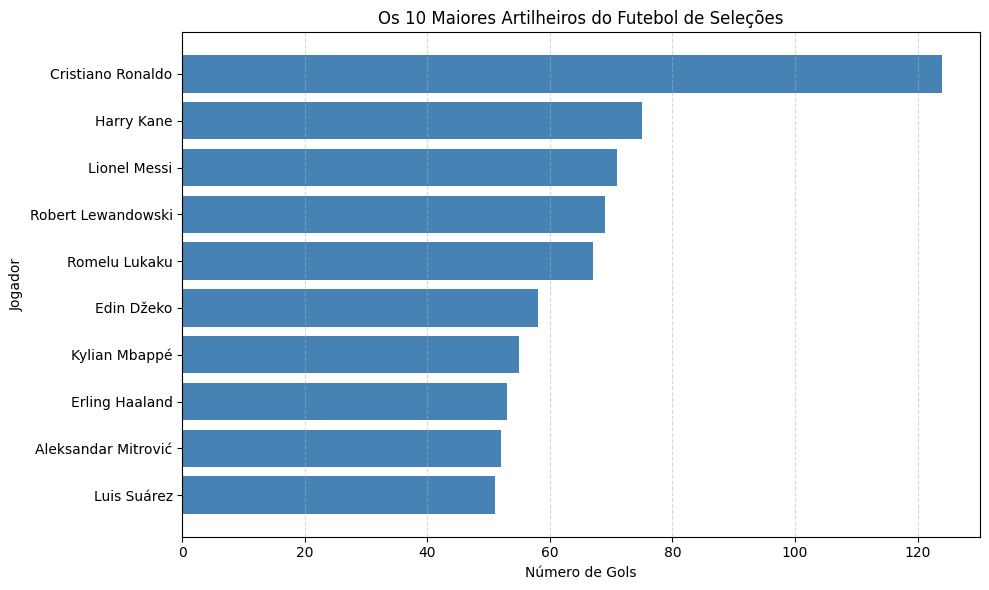

In [2]:
# Filtra registros sem autor identificado e ordena os 10 maiores artilheiros
top10_artilheiros = (
    df_limpo[df_limpo["scorer"] != "Desconhecido"]["scorer"]
    .value_counts()
    .head(10)
    .sort_values(ascending=True)
)

# Cria o gráfico de barras horizontais ordenadas no matplotlib
plt.figure(figsize=(10, 6))
plt.barh(top10_artilheiros.index, top10_artilheiros.values, color="steelblue")
plt.title("Os 10 Maiores Artilheiros do Futebol de Seleções")
plt.xlabel("Número de Gols")
plt.ylabel("Jogador")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

**O que o gráfico mostra:** O gráfico de barras horizontais ordenadas compara o total de gols marcados pelos dez maiores artilheiros internacionais da base. Observa-se uma ampla liderança de Cristiano Ronaldo no topo do ranking, abrindo uma vantagem expressiva sobre o segundo colocado (Harry Kane) e sobre Lionel Messi, enquanto os demais jogadores da lista apresentam volumes muito próximos entre si, concentrados na faixa entre 50 e 70 gols.

## 2. Pergunta de Tendência / Relação
**Como o volume anual de gols registrados evoluiu ao longo do tempo e quais padrões sazonais aparecem na série histórica?**

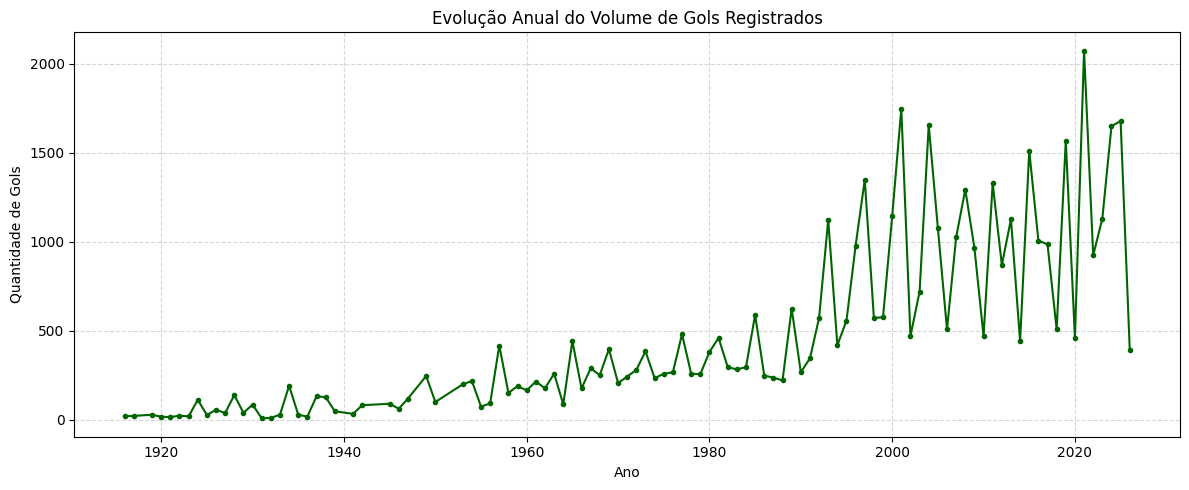

In [3]:
# Extrai o ano das partidas e soma a quantidade de gols por ano
anos = pd.to_datetime(df_limpo["date"]).dt.year
gols_por_ano = df_limpo.groupby(anos).size()

# Cria o gráfico de linha no matplotlib
plt.figure(figsize=(12, 5))
plt.plot(
    gols_por_ano.index,
    gols_por_ano.values,
    color="darkgreen",
    linewidth=1.5,
    marker="o",
    markersize=3,
)
plt.title("Evolução Anual do Volume de Gols Registrados")
plt.xlabel("Ano")
plt.ylabel("Quantidade de Gols")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

**O que o gráfico mostra:** A linha temporal mostra uma tendência de crescimento no volume de gols ao longo das décadas, marcada por fortes ciclos do calendário internacional: anos de Eliminatórias concentram picos de gols, enquanto anos de torneios finais ou de transição (como 2018) apresentam quedas para a faixa de 500 gols. Períodos históricos atípicos também aparecem no traçado: entre 1942 e 1945 há um intervalo sem pontos devido à pausa na Segunda Guerra Mundial, e em 2020 ocorre uma queda brusca para cerca de 460 gols durante a pandemia, seguida pelo maior pico da série em 2021 (mais de 2.000 gols) pelo acúmulo de partidas adiadas.

## 3. Pergunta de Distribuição
**Como os gols estão concentrados ao longo dos minutos das partidas e onde aparecem os valores atípicos (outliers)?**

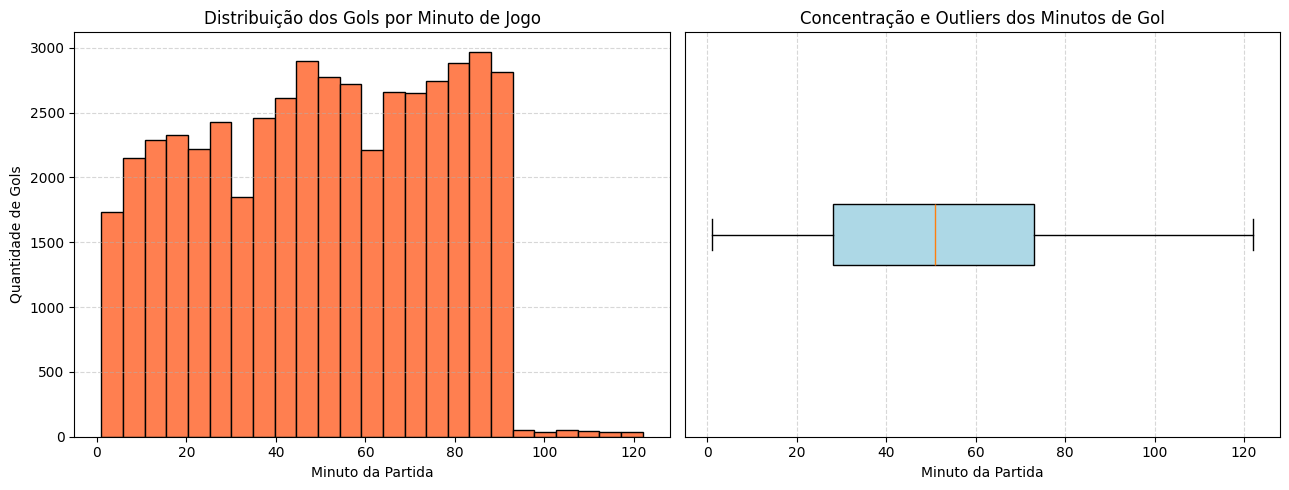

In [4]:
minutos = df_limpo["minute"].dropna()

# Cria dois gráficos lado a lado no matplotlib: Histograma e Boxplot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# 1. Histograma (concentração)
ax1.hist(minutos, bins=25, color="coral", edgecolor="black")
ax1.set_title("Distribuição dos Gols por Minuto de Jogo")
ax1.set_xlabel("Minuto da Partida")
ax1.set_ylabel("Quantidade de Gols")
ax1.grid(axis="y", linestyle="--", alpha=0.5)

# 2. Boxplot (outliers)
ax2.boxplot(
    minutos,
    vert=False,
    patch_artist=True,
    boxprops=dict(facecolor="lightblue"),
)
ax2.set_title("Concentração e Outliers dos Minutos de Gol")
ax2.set_xlabel("Minuto da Partida")
ax2.set_yticks([])
ax2.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

**O que o gráfico mostra:** O histograma e o boxplot mostram que a grande maioria dos gols está concentrada dentro dos **90 minutos regulamentares** de partida, com a caixa central (50% dos dados) situada entre os minutos 28 e 73, mediana próxima aos 51 minutos e picos visíveis no fim de cada tempo (45' e 90'). Embora o boxplot estenda sua haste direita até o minuto 122 sem marcar pontos isolados pela regra estatística, o histograma evidencia claramente que os registros acima de 90 minutos (barras baixas entre 91' e 120') representam eventos atípicos e pouco frequentes, correspondentes aos gols marcados nas **prorrogações** de jogos eliminatórios.